# Exercise 4 - Solution
***

> **Aim:** To read in and plot earthquake data from 2019 on the continental USA.

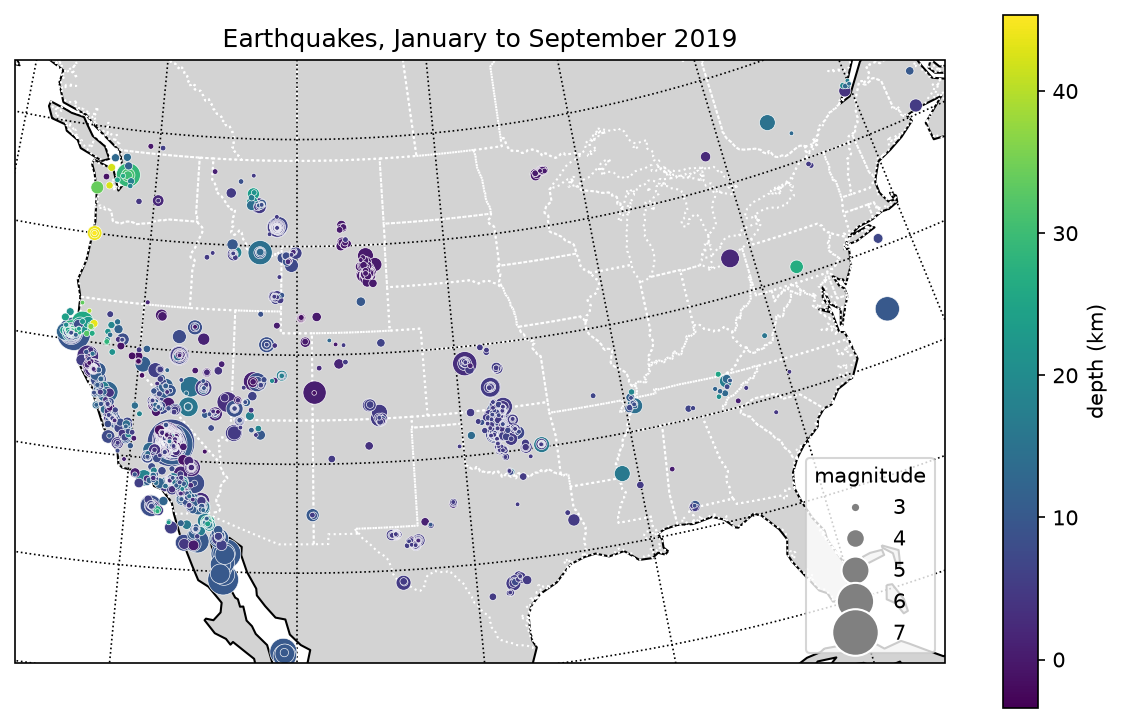

In [1]:
import pandas as pd
import cartopy as ctp
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
#we need this next import to manually construct the legend
from matplotlib.lines import Line2D

#read in the earthquake data, which is in the exercises folder
df = pd.read_csv('../exercises/data/us_eqs.csv', header=0, index_col=None)

#define the plot area, with subplot_kw passing the map projection (and its central longitude) to the axes
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.AlbersEqualArea(central_longitude=-110)})
#set the axes extent so that the plot focuses on the continental US
ax.set_extent([-125, -75, 25, 50], crs=ccrs.PlateCarree())

#add coastlines, with zorder=0 so that everything else is drawn on top of the land
feature = cfeature.NaturalEarthFeature(
        name='coastline', category='physical',
        scale='110m',
        edgecolor='#000000', facecolor='lightgrey')
ax.add_feature(feature, zorder=0)

#add gridlines, plotting them behind the landmass
gl = ax.gridlines(linestyle=':', color='k', zorder=-1);

#add the state boundaries, using Cartopy's ready-made feature
ax.add_feature(cfeature.STATES, edgecolor='white', linestyle=':')

#sort the dataframe so that the largest earthquakes are plotted first, and the smaller ones on top of them
df = df.sort_values('mag', ascending=False)

#scatter() sets the *area* of each symbol with 's'. Magnitudes are small numbers (2.5 to about 7),
# so we need to transform them to get a useful range of sizes. Here we use (magnitude - 2) squared,
# which keeps the smallest earthquakes visible and makes the large ones stand out.
size_fac = 20
def mag_to_size(m):
    """Return the scatter() symbol area for an earthquake of magnitude m."""
    return size_fac * (m - 2)**2

#plot the points, coloured by depth using the 'viridis' colormap, and scaled by magnitude
# scatter picks the colour for each point from the colormap for us
im = ax.scatter(df.longitude, df.latitude, c=df.depth, cmap='viridis', s=mag_to_size(df.mag),
                edgecolor='white', linewidths=0.3, zorder=2, transform=ccrs.PlateCarree())

#add the colour bar, using the object that scatter() gave back to us
fig.colorbar(im, ax=ax, label='depth (km)')

#plot the legend. Line2D's 'markersize' is the symbol's diameter rather than its area,
# so we take the square root of the size we gave scatter() above
legend_mags = [3, 4, 5, 6, 7]
legend_elements = [Line2D([0], [0], marker='o', ls='', label=f'{m}', markeredgecolor='white',
                          markerfacecolor='grey', markersize=mag_to_size(m)**0.5)
                   for m in legend_mags]

ax.legend(handles=legend_elements, title='magnitude', loc='lower right')

ax.set_title('Earthquakes, January to September 2019');

#save the map to a file
fig.savefig('exercise4_earthquakes.png', dpi=300, bbox_inches='tight')

The above map shows that seismicity is concentrated in the western US.  Why is seismicity focused here?  And is our result consistent with the USGS's __[long-term seismic hazard forecast](https://www.usgs.gov/media/images/national-seismic-hazard-model-2023-chance-damaging-earthquake-shaking)__?

Why is there a band of seismicity running across the central US?

## Your turn answers
***

Model answers to the **Your turn** and **Fix the bug** tasks in `Exercise4.ipynb`, in the order they appear.  They use variables from earlier in that notebook, so they are shown here as code to read rather than to run.

### A Robinson projection

```python
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.coastlines(resolution='110m')
ax.stock_img();
gl = ax.gridlines(draw_labels=True, linestyle=':', color='k');
```

### Fix the bug: longitude and latitude

```python
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Mercator())
ax.set_extent([-30, 60, -10, 70], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')

#Cambridge is at 52.2 N, 0.12 E
# transform=ccrs.PlateCarree() tells Cartopy that we are giving it longitudes and latitudes (more on this in section 4.2)
# ax.plot() gives back a list of the lines it drew: [0] picks out the first (and only) one, our star
star = ax.plot(0.12, 52.2, 'r*', markersize=15, transform=ccrs.PlateCarree())[0]

#get_xydata() gives the position we plotted the star at
check('cambridge', star.get_xydata()[0])
```

### A map centred on New Zealand

```python
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson(central_longitude=175))
ax.coastlines(resolution='110m')
ax.stock_img();
```

### Counting the ice caps

```python
n_icecaps = len(poly_geoms)
check('ice caps', n_icecaps)
```

### Setting up the map (the faded example)

```python
#----------- same as before -----------------------
poly_geoms = poly_jokull()

#Your turn: fill in the blanks to set up the figure, the axes with a Mercator projection centred on -15,
# and the map extent, just as in the ice cap map above
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Mercator(central_longitude=-15))
ax.set_extent([-25, -13, 63, 67.], crs=ccrs.PlateCarree())

feature = ctp.feature.NaturalEarthFeature(
    name='coastline', category='physical',
    scale='10m',
    edgecolor='#000000', facecolor='lightgrey')
ax.add_feature(feature, zorder=0)

gl = ax.gridlines(draw_labels=True, linestyle=':', color='k', zorder=-1);
gl.top_labels = False
gl.right_labels = False
#----------- end of same as before -----------------------

#let's update the ice caps to have a zorder of 2, so they plot on top of the rifts
for p in poly_geoms:
    x = ax.add_geometries([p], crs=ccrs.PlateCarree(), facecolor='white', zorder=2)

# run our new function
rift_polys = poly_rift('data/fisswarms_fil.xy')

#as with the ice caps, we loop through each polygon, setting zorder=1 so they plot below the ice caps
# setting the color to that of fresh lava, 'rosybrown'
for p in rift_polys:
    x = ax.add_geometries([p], crs=ccrs.PlateCarree(), facecolor='rosybrown', zorder=1)
```

### Counting large eruptions

```python
n_big = len(dfvs[dfvs['Volume(km3)'] > 10])
check('big eruptions', n_big)
```